In [1]:
import mina
import scanpy as sc
import scanpy.external as sce
import numpy as np
import decoupler as dc
import math
import mofaflex as mf
import mudata as md
import pandas as pd
import matplotlib.pyplot as plt
import squidpy as sq

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Versio

Importing the dtw module. When using in academic works please cite:
  T. Giorgino. Computing and Visualizing Dynamic Time Warping Alignments in R: The dtw Package.
  J. Stat. Soft., doi:10.18637/jss.v031.i07.



In [2]:
adata = sc.read_h5ad("/nfs/research/saezrodriguez/data/ERC_CartoHostBug/MERFISH/full_adata.h5ad")

/tmp/ipykernel_3818569/3362090997.py:1: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


In [3]:
adata = adata[adata.obs["Sample_type"] != "DSS21"].copy()
# Take out "DSS" and make Healthy 0 from Sample_type
adata.obs["time"] = adata.obs["Sample_type"].apply(lambda x: 0 if x == "Healthy" else x.replace("DSS", ""))
adata.obs["time"] = adata.obs["time"].astype(str).astype(int)
# add obs names
adata.obs_names = adata.obs["Cell_ID"].to_list()

# Generating sample meta-data
metadata = mina.up.extract_metadata_from_obs(obs=adata.obs, groupby="Slice_ID", sort=False)
metadata["Sample_type"] = pd.Categorical(metadata["Sample_type"], categories=["Healthy", "DSS3", "DSS9", "DSS21", "DSS35"], ordered=True)

/tmp/ipykernel_3818569/1083909564.py:1: UserWarning: Observation names are not unique. To make them unique, call `.obs_names_make_unique`.


## Expression model

In [4]:
#Define order of time points
pdata = dc.pp.pseudobulk(adata, sample_col="Slice_ID", groups_col="Tier1")

contaminants_dict = mina.up.get_contaminant_genes(pdata,
                      view_group="Tier1",
                      min_count=5,
                      min_total_count=10,
                      large_n=10,
                      min_prop=0.4,
                      lfc_threshold=1.5,
                      p_threshold=0.05)

# Manipulations on pdata
pdata.obs = pdata.obs.set_index("Slice_ID", drop=False)
pdata.obs.index.name = None

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/decoupler/pp/anndata.py:520: RuntimeWarning: invalid value encountered in divide
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/decoupler/pp/anndata.py:520: RuntimeWarning: invalid value encountered in divide
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/decoupler/pp/anndata.py:520: RuntimeWarning: invalid value encountered in divide
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/legacy_api_wrap/__init__.py:88: UserWarning: Some cells have zero counts
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/decoup

In [5]:
# Make list of adatas per pseudobulk cell type
anndata_dict = mina.up.split_anndata_by_celltype(pdata=pdata, grouping="Tier1")

# Adding gene expression total counts - TODO add to upstream as a function
for _cell_type, adata_raw in anndata_dict.items():
    # Sum across observations (rows) for each gene (column)
    if hasattr(adata_raw.X, "toarray"):
        # Sparse matrix case
        total_counts = adata_raw.X.sum(axis=0).A1  # returns 1D array
    else:
        total_counts = adata_raw.X.sum(axis=0)  # numpy array

    # Add to .var
    adata_raw.var["total_counts"] = total_counts

mina.up.filt.filter_anndata_by_ncells(anndata_dict, min_cells=10)
# From all the possible samples, let's ask for at least 40%
n_samples = len(metadata.index)
min_samples =  math.trunc((n_samples * 0.9))
mina.up.filter_views_by_samples(anndata_dict, min_rows=min_samples)
mina.up.filter_genes_byexpr(anndata_dict, min_count=5, min_prop=0.4)
mina.up.filter_views_by_genes(anndata_dict, min_genes_per_view=50)
mina.up.filter_samples_by_coverage(anndata_dict, threshold=0, min_prop=0.95)
mina.up.filter_views_by_samples(anndata_dict, min_rows=min_samples)
mina.up.save_raw_counts(anndata_dict, layer_name="raw_counts")
mina.up.norm_log(anndata_dict, target_sum=1e5, exclude_highly_expressed=False, max_value=None, center=True)
contaminants_dict = {ct:values for ct, values in contaminants_dict.items() if ct in anndata_dict.keys()}
mina.up.filter_genes_by_celltype(anndata_dict, contaminants_dict)
mina.up.utils.append_view_to_var(anndata_dict)
mina.up.utils.append_view_to_var(anndata_dict)

Raw counts saved in the 'raw_counts' layer for each AnnData object.
Normalization, log-transformation, and scaling complete for all AnnData objects with target_sum = 100000.0.


### Classic MOFAcell
Using the Horseshoe prior which has been shown in MuVI that works better

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


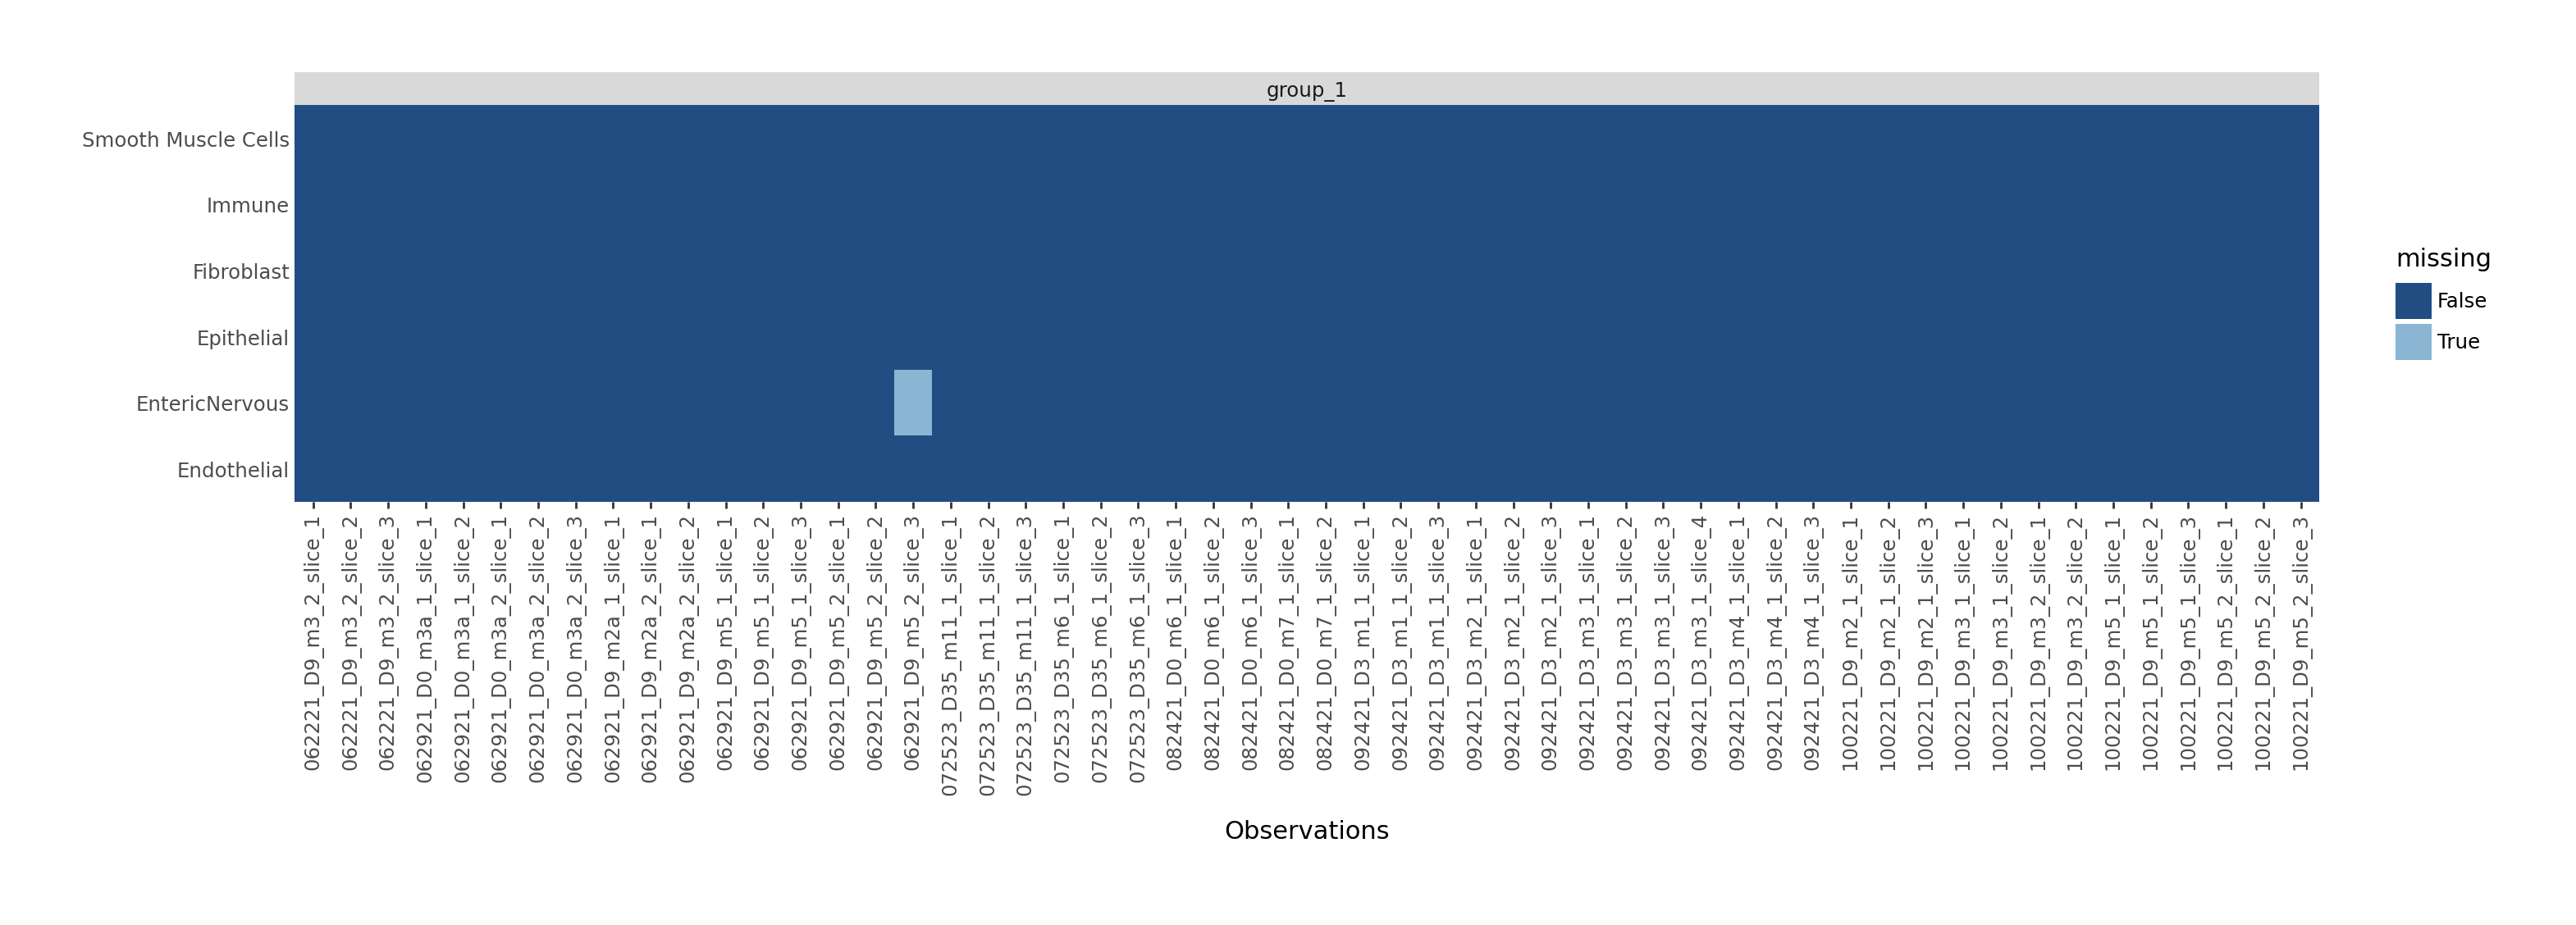

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by defau

100%|██████████| 10000/10000 [25:47<00:00,  6.46epoch/s, Loss=3.83e+3]
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


In [6]:
# This is necessary before any model fit!
mdata = md.MuData(anndata_dict)
# Fitting model
model = mf.terms.MofaFlex(n_factors=10, weight_prior="Horseshoe", init_factors="pca", nonnegative_weights=False, nonnegative_factors=False)
model.fit(mdata, seed=42, save_path=False, lr=0.001, early_stopper_patience=1000, likelihoods="Normal")

In [7]:
amodel_MOFA = mina.down.model_to_anndata(
    anndata_dict=anndata_dict,
    metadata=metadata,
    model=model,
)

amodel_MOFA.obs["Sample_type"] = pd.Categorical(amodel_MOFA.obs["Sample_type"], 
                                           categories = ["Healthy", "DSS3", "DSS9", "DSS35"],
                                           ordered=True)

amodel_MOFA.write_h5ad("./results/MERFISH/gex_model_MOFA.h5ad")                        

### Compositional baseline
Here we will use the homogenized baseline to check differences in time

In [8]:
clr_props_adata = mina.up.get_cell_props(adata, "Slice_ID", "TierMINA", metadata)
mina.up.utils.append_view_to_var({"clr_comps":clr_props_adata})

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mina/up/utils.py:486: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mina/up/utils.py:497: UserWarning: 
AnnData expects .obs.index to contain strings, but got values like:
    ['062221_D9_m3_2_slice_1', '062221_D9_m3_2_slice_2', '062221_D9_m3_2_slice_3', '062921_D0_m3a_1_slice_1', '062921_D0_m3a_1_slice_2']

    Inferred to be: categorical



/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


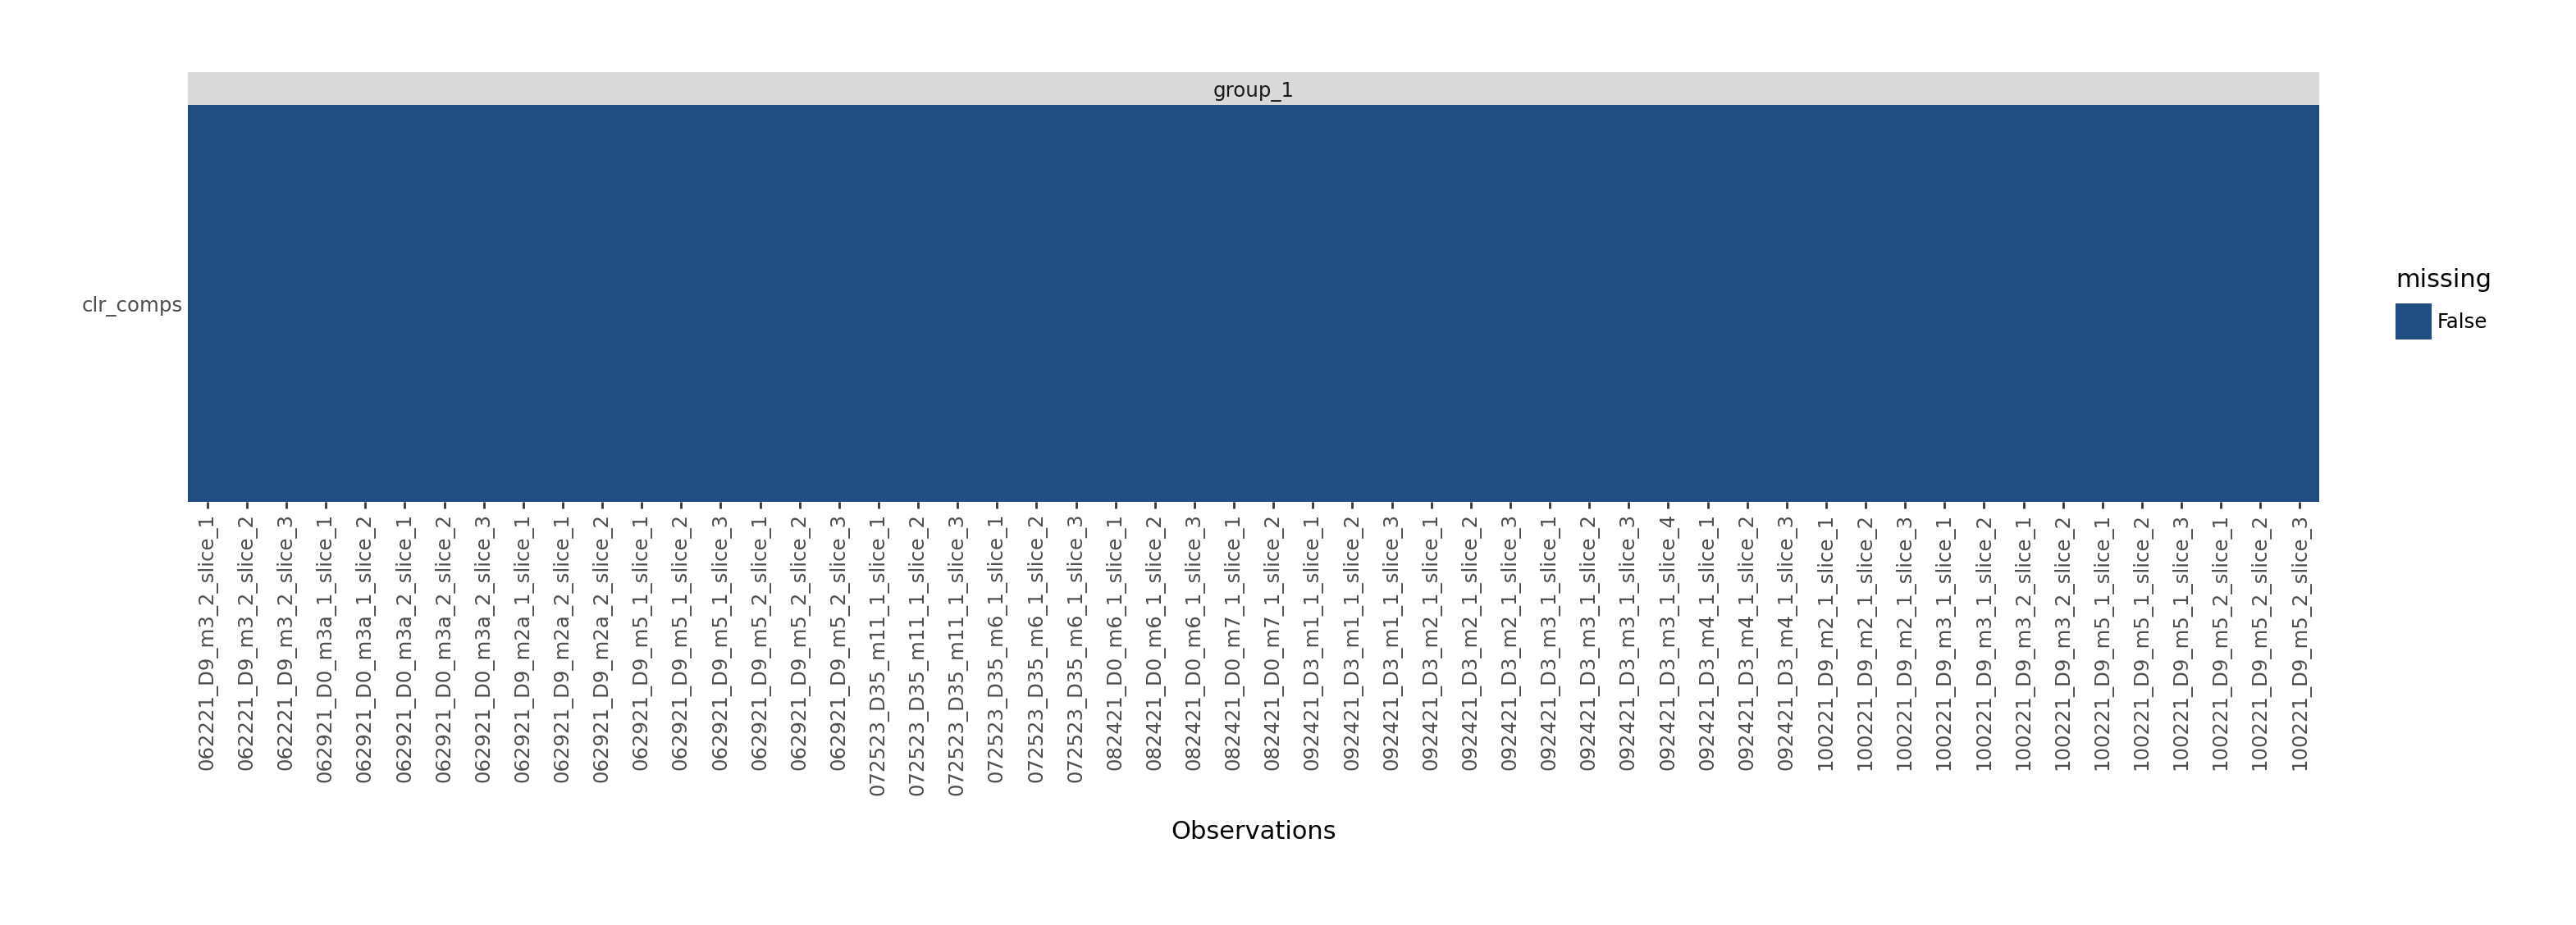

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by defau

 96%|█████████▋| 9647/10000 [05:25<00:11, 29.65epoch/s, Loss=41.8]
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


In [9]:
mdata = md.MuData({"clr_comps":clr_props_adata})

# Fitting model
model_comp = mf.terms.MofaFlex(n_factors=10, weight_prior="Horseshoe", 
                               nonnegative_weights=False, nonnegative_factors=False,
                               init_factors= "pca")

model_comp.fit(mdata, seed=42, save_path=False, 
               lr=0.001, early_stopper_patience=1000, 
               likelihoods="Normal")

In [10]:
amodel_comp = mina.down.model_to_anndata(
    anndata_dict={"clr_comps":clr_props_adata},
    metadata=metadata,
    model=model_comp,
)

amodel_comp.obs["Sample_type"] = pd.Categorical(amodel_comp.obs["Sample_type"], 
                                           categories = ["Healthy", "DSS3", "DSS9", "DSS35"],
                                           ordered=True)

amodel_comp.write_h5ad("./results/MERFISH/comp_model_MOFA.h5ad")                        

### Spatial baseline

In [11]:
spatial_interaction_adata = mina.up.get_nhood_enrichment_feats(
    adata,
    sample_key="Slice_ID",
    cluster_key="TierMINA",
    diagonal = True, # To co
    n_perms=1000,
    metadata=metadata
)

# Don't forget to add the view name to the variables for compatibility
mina.up.utils.append_view_to_var({"Spatial":spatial_interaction_adata})

INFO     Creating graph using `None` transform and `1` libraries.                                                  


100%|██████████| 1000/1000 [00:02<00:00, 442.80/s]
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/squidpy/gr/_nhood.py:220: RuntimeWarning: invalid value encountered in divide


INFO     Creating graph using `None` transform and `1` libraries.                                                  


100%|██████████| 1000/1000 [00:02<00:00, 484.03/s]


INFO     Creating graph using `None` transform and `1` libraries.                                                  


100%|██████████| 1000/1000 [00:01<00:00, 600.30/s]
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/squidpy/gr/_nhood.py:220: RuntimeWarning: invalid value encountered in divide


... (98 outputs left out)

INFO     Creating graph using `None` transform and `1` libraries.                                                  


100%|██████████| 1000/1000 [00:01<00:00, 769.67/s]
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/squidpy/gr/_nhood.py:220: RuntimeWarning: invalid value encountered in divide


INFO     Creating graph using `None` transform and `1` libraries.                                                  


100%|██████████| 1000/1000 [00:01<00:00, 867.61/s]


/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/anndata/_core/views.py:154: RuntimeWarning: invalid value encountered in subtract


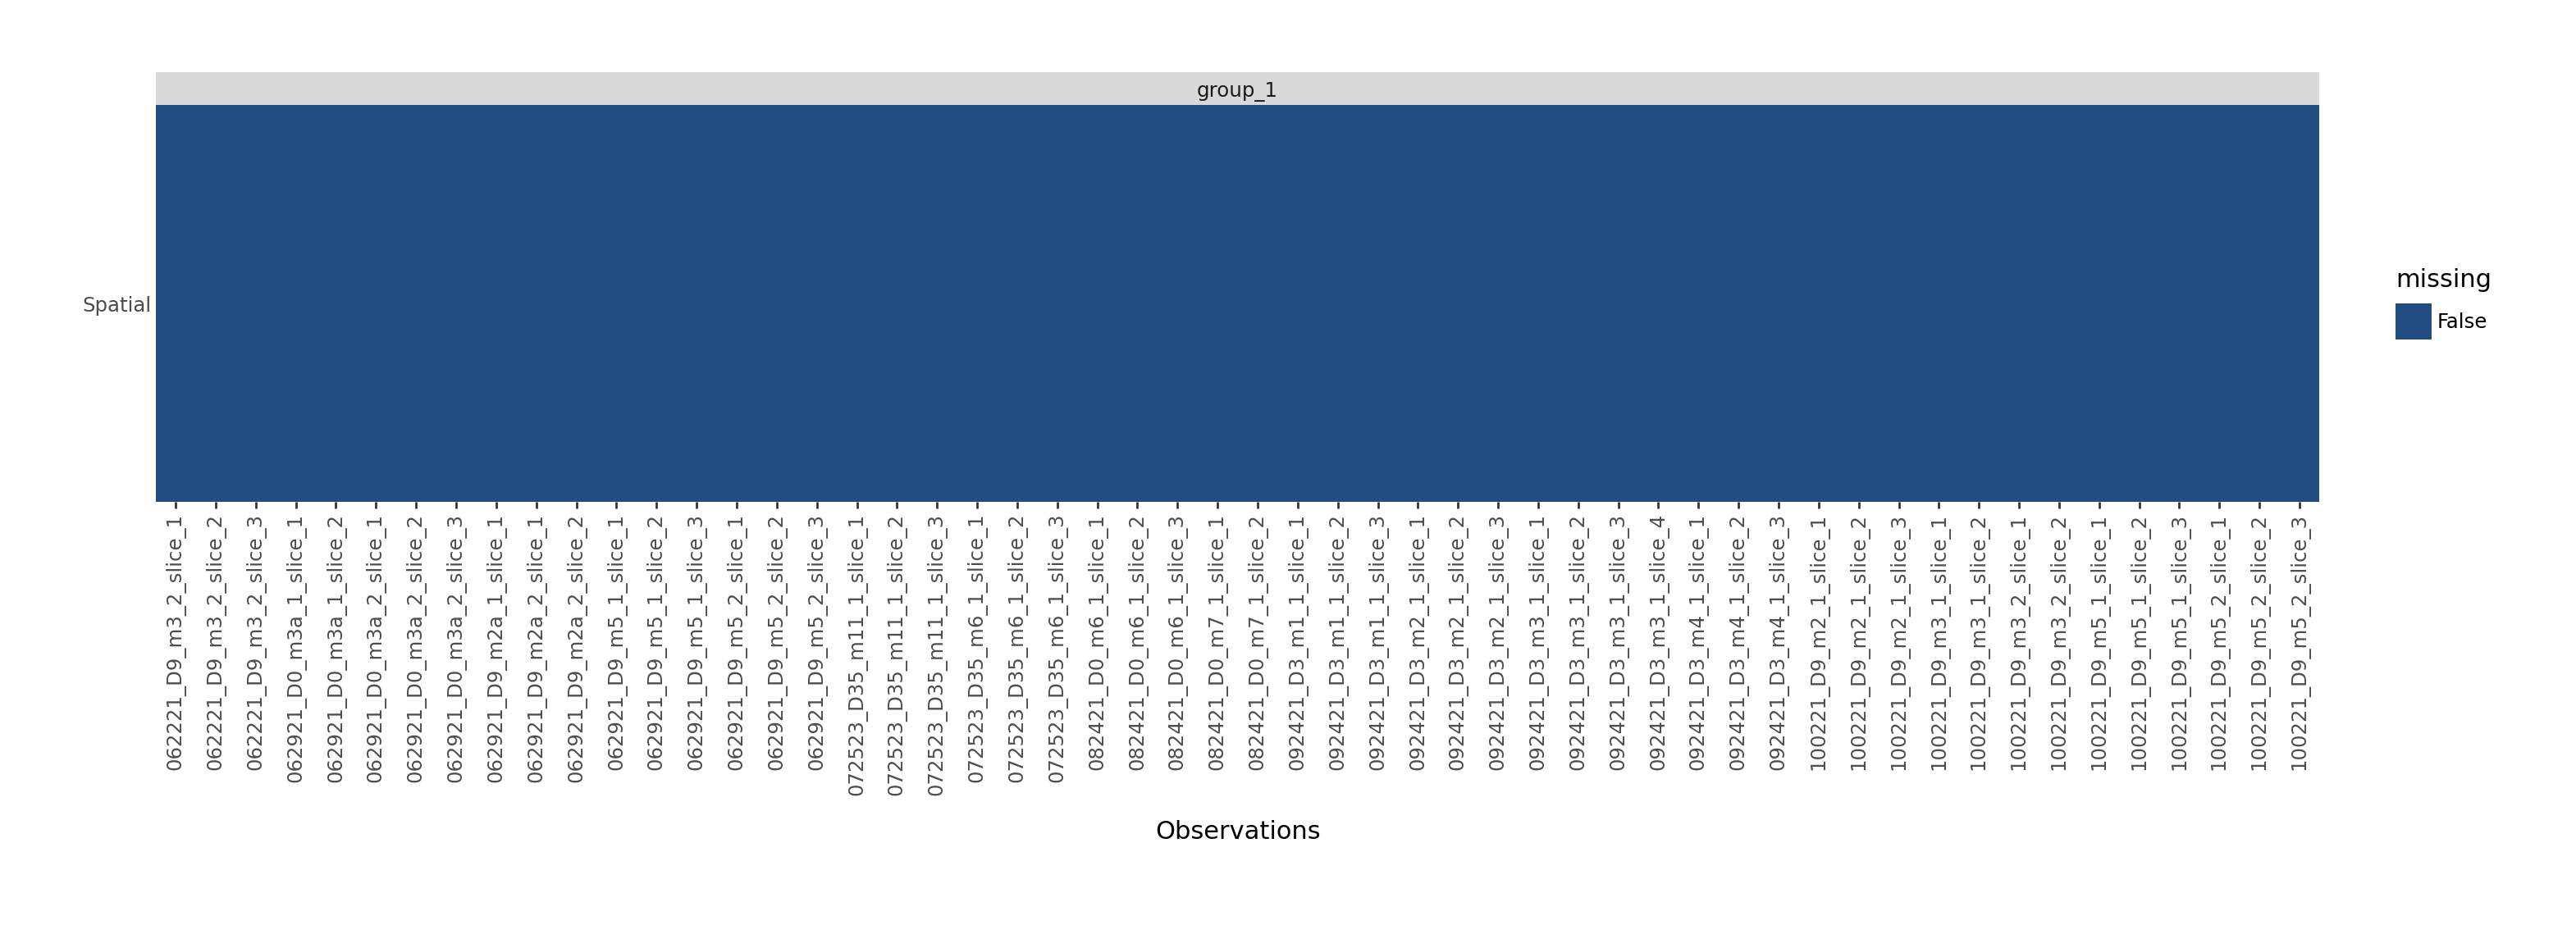

/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by defau

100%|██████████| 10000/10000 [05:29<00:00, 30.37epoch/s, Loss=925]   
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1471: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.
/nfs/research/saezrodriguez/rico/MINA_ms/.venv/lib/python3.12/site-packages/mudata/_core/mudata.py:1322: FutureWarning: From 0.4 .update() will not pull obs/var columns from individual modalities by default anymore. Set mudata.set_options(pull_on_update=False) to adopt the new behaviour, which will become the default. Use new pull_obs/pull_var and push_obs/push_var methods for more flexibility.


In [12]:
mdata = md.MuData({"Spatial":spatial_interaction_adata})

# Fitting model
model_sp = mf.terms.MofaFlex(n_factors=10, weight_prior="Horseshoe", 
                               nonnegative_weights=False, nonnegative_factors=False,
                               init_factors= "pca")

model_sp.fit(mdata, seed=42, save_path=False, lr=0.001, early_stopper_patience=1000, likelihoods="Normal")

In [13]:
amodel_sp = mina.down.model_to_anndata(
    anndata_dict={"Spatial":spatial_interaction_adata},
    metadata=metadata,
    model=model_sp,
)

amodel_sp.obs["Sample_type"] = pd.Categorical(amodel_sp.obs["Sample_type"], 
                                           categories = ["Healthy", "DSS3", "DSS9", "DSS35"],
                                           ordered=True)

amodel_sp.write_h5ad("./results/MERFISH/sp_model_MOFA.h5ad")                        